<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/QUIZ1/DBScan%20Revisi/DBSCAN_COSINE_REVISI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputDBscanCosine'
os.makedirs(OUTPUT_DIR, exist_ok=True)

1. Data Understanding

1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')
print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)

print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


1.2 Data Preview

In [3]:
print("5 Baris Pertama Dataset:")
display(df.head())

print("\nNama Semua Kolom:")
print(df.columns.tolist())

5 Baris Pertama Dataset:


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,33554,19.0,Male,France,Teacher,PhD,Employed,NaN,58,Hybrid,...,No,No,Poor,7.0,53.0,26,52,Needs Attention,Reduce Workload,Moderate
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,Yes,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate
2,200,42.0,Male,United Kingdom,Police Officer,PhD,Unemployed,NaN,59,No,...,No,No,Average,6.0,50.0,28,46,Needs Attention,Increase Physical Activity,Moderate
3,12448,22.0,Other,Singapore,Lawyer,PhD,Student,NaN,49,Yes,...,No,Yes,Average,5.0,29.0,19,58,Needs Attention,Take Regular Breaks,Moderate
4,39490,62.0,Other,Russia,Doctor,Master,Self-Employed,NaN,39,Yes,...,Yes,No,Poor,1.0,62.0,30,50,Needs Attention,Take Regular Breaks,Moderate



Nama Semua Kolom:
['Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


1.3 Tipe data dan Missing Values

In [4]:
print('Tipe Data:')
print(df.dtypes)

print('\nJumlah Missing Value:')
missing = df.isnull().sum()

missing[missing > 0]

Tipe Data:
Person_ID                          int64
Age                              float64
Gender                            object
Country                           object
Occupation                        object
Education_Level                   object
Employment_Status                 object
Monthly_Income_USD               float64
Work_Hours_Per_Week                int64
Remote_Work                       object
Job_Satisfaction                 float64
Work_Life_Balance                float64
Sleep_Hours                      float64
Sleep_Quality                     object
Stress_Level                      object
Anxiety_Score                    float64
Depression_Score                 float64
Mood_Score                       float64
Emotional_Stability                int64
Physical_Activity_Hours          float64
Exercise_Frequency                object
Meditation_Minutes               float64
Screen_Time_Hours                float64
Social_Media_Hours               float64
Gamin

,0
Age,28
Monthly_Income_USD,1450
Job_Satisfaction,37
Work_Life_Balance,60
Sleep_Hours,85
Anxiety_Score,80
Depression_Score,73
Mood_Score,91
Physical_Activity_Hours,100
Meditation_Minutes,122


1.4 Identifikasi Kolom yang Digunakan

In [5]:
# Kolom numerik asli
numeric_columns = df.select_dtypes(include='number').columns

# Menghapus identifier
numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

# Kolom kategorikal yang akan di-encoding
categorical_columns = [
    'Remote_Work',
    'Sleep_Quality',
    'Stress_Level',
    'Exercise_Frequency',
    'Alcohol_Consumption',
    'Smoking',
    'Healthy_Diet',
    'Chronic_Stress',
    'Family_History_Mental_Illness',
    'Therapy_Attendance',
    'Support_System',
    'Mental_Health_Status'
]

print('Kolom Numerik:')
print(numeric_columns.tolist())

print('\nKolom Kategorikal yang akan di-encoding:')
print(categorical_columns)

Kolom Numerik:
['Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days']

Kolom Kategorikal yang akan di-encoding:
['Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status']


1.5 Statistik Deskriptif

In [6]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4972.0,41.684433,13.999166,18.0,29.00,42.0,54.00,65.0
Monthly_Income_USD,3550.0,6282.846197,3331.236477,500.0,3307.25,6370.5,9170.75,11998.0
Work_Hours_Per_Week,5000.0,45.032800,14.636945,20.0,32.00,45.0,58.00,70.0
Job_Satisfaction,4963.0,5.601048,2.876333,1.0,3.00,6.0,8.00,10.0
Work_Life_Balance,4940.0,5.520040,2.896089,1.0,3.00,6.0,8.00,10.0
Sleep_Hours,4915.0,6.956765,1.722117,4.0,5.50,6.9,8.40,10.0
Anxiety_Score,4920.0,40.857520,25.983071,0.0,20.00,40.0,60.00,100.0
Depression_Score,4927.0,41.036736,26.155498,0.0,20.00,40.0,60.00,100.0
Mood_Score,4909.0,59.207374,25.762049,0.0,41.00,59.0,80.00,100.0
Emotional_Stability,5000.0,59.003000,26.060461,0.0,40.00,60.0,80.00,100.0


1.6 Visualisasi Distribusi Data

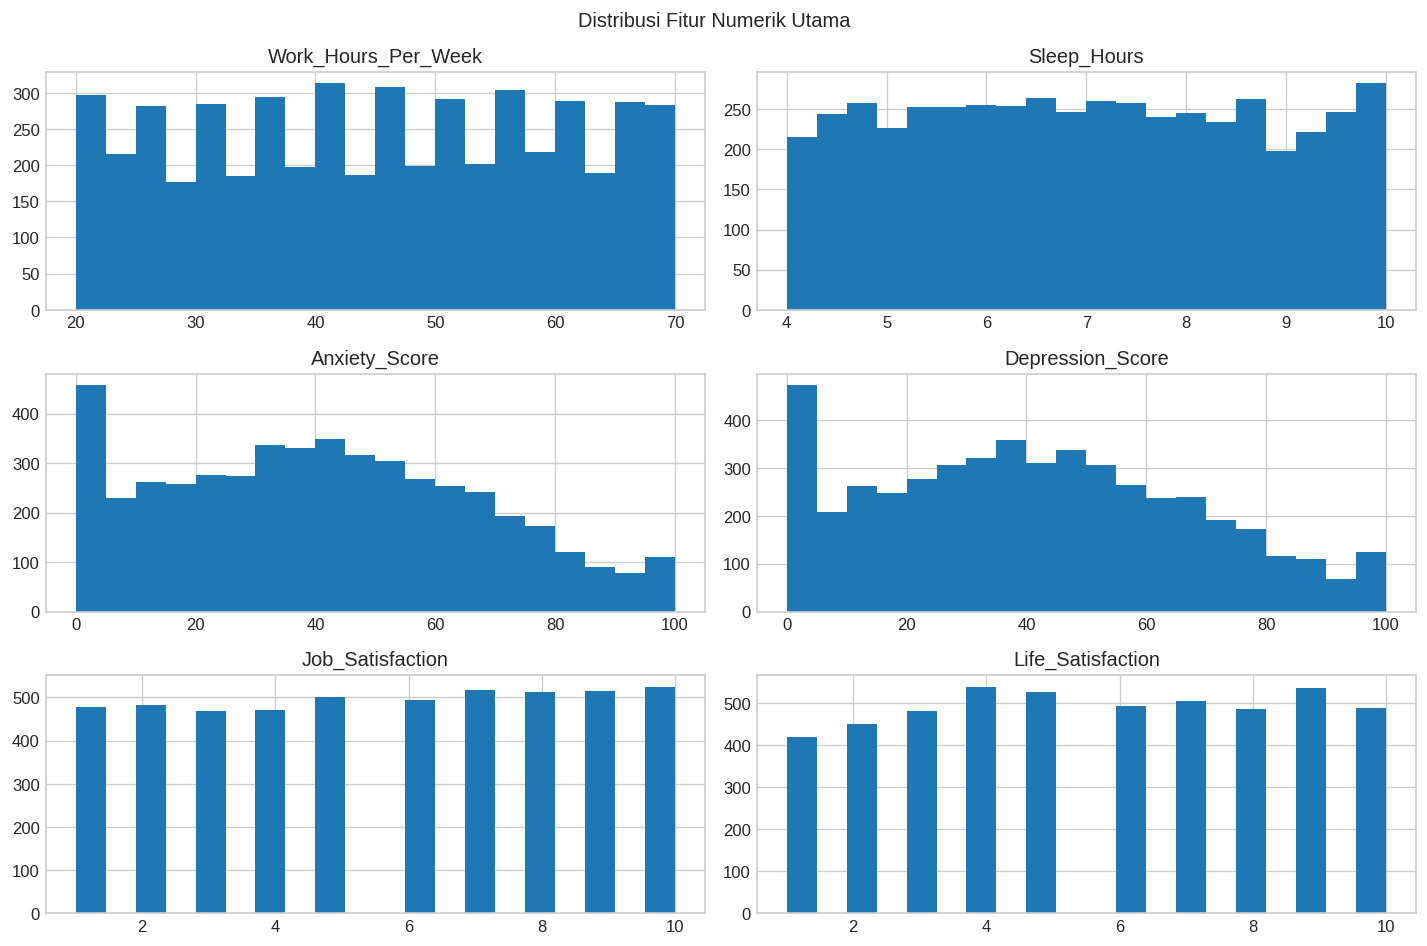

In [7]:
selected_features = [
    'Work_Hours_Per_Week',
    'Sleep_Hours',
    'Anxiety_Score',
    'Depression_Score',
    'Job_Satisfaction',
    'Life_Satisfaction'
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle('Distribusi Fitur Numerik Utama')
plt.tight_layout()
plt.show()

1.7 Visualisasi Deteksi Outlier

In [8]:
numeric_columns_outlier = df.select_dtypes(
    include='number'
).columns

numeric_columns_outlier = numeric_columns_outlier.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

numeric_data = df[numeric_columns_outlier]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (numeric_data < lower_bound) |
    (numeric_data > upper_bound)
)

In [9]:
outlier_summary = pd.DataFrame({
    'Jumlah Outlier': outlier_mask.sum(),
    'Persentase (%)': (
        outlier_mask.sum() / len(df) * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    'Jumlah Outlier',
    ascending=False
)

outlier_summary

,Jumlah Outlier,Persentase (%)
Age,0,0.0
Monthly_Income_USD,0,0.0
Work_Hours_Per_Week,0,0.0
Job_Satisfaction,0,0.0
Work_Life_Balance,0,0.0
Sleep_Hours,0,0.0
Anxiety_Score,0,0.0
Depression_Score,0,0.0
Mood_Score,0,0.0
Emotional_Stability,0,0.0


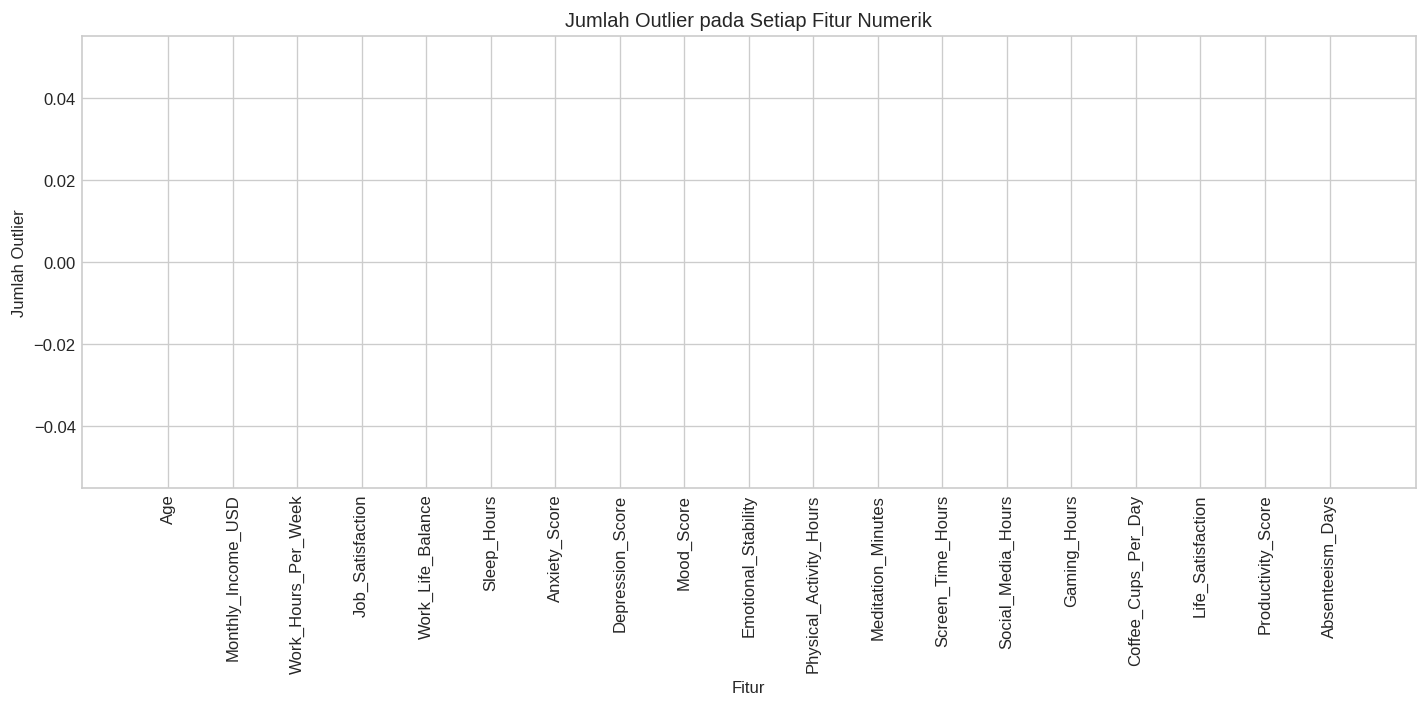

In [10]:
plt.figure(figsize=(12, 6))

plt.bar(
    outlier_summary.index,
    outlier_summary['Jumlah Outlier']
)

plt.title('Jumlah Outlier pada Setiap Fitur Numerik')
plt.xlabel('Fitur')
plt.ylabel('Jumlah Outlier')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

2.1 Seleksi Kolom

In [11]:
selected_columns = list(numeric_columns) + categorical_columns

X = df[selected_columns].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


2.2 Encoding Data Kategorikal

In [12]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 0,
        'Yes': 1
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 0,
        'Yes': 1
    },

    'Support_System': {
        'Poor': 0,
        'Average': 1,
        'Good': 2,
        'Excellent': 3
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():
    X[column] = X[column].map(mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,0,0,0,0.0,0,1
1,2,3,1,3,0,1,0,0,1,0.0,3,1
2,0,3,1,0,0,1,0,0,0,0.0,1,1
3,2,2,2,3,0,1,1,1,0,1.0,1,1
4,2,3,1,1,0,1,0,0,1,0.0,0,1


2.3 Penanganan Missing Values

In [13]:
print('Missing value sebelum preprocessing:')
print(X.isnull().sum())

X = X.fillna(X.mean())

print(
    '\nJumlah missing value setelah preprocessing:',
    X.isnull().sum().sum()
)

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

2.4 Penanganan Outlier

In [14]:
# Karena tidak, tidak dilakukan

2.5 Standardisasi

In [15]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.000000,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,-0.982159,-0.403808,-0.973550,-1.014305,-1.351177,0.353005
1,0.452453,0.000000,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005
2,0.022608,0.000000,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,-0.973550,-1.014305,-0.453862,0.353005
3,-1.410210,0.000000,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,1.018165,2.476422,-0.973550,0.994449,-0.453862,0.353005
4,1.455425,0.000000,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,-1.351177,0.353005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.667376,0.195668,1.705936,-1.605736,-0.180672,-0.618989,1.518814,2.001572,-1.575281,-1.343280,...,1.811640,-0.472624,1.031702,-0.989654,-0.982159,2.476422,-0.973550,-1.014305,0.443453,1.610144
4996,0.452453,-0.044840,-0.617185,-0.907749,0.166747,-0.618989,0.781572,0.345256,-0.282377,-0.959519,...,0.390969,-1.360347,1.031702,1.010455,1.018165,-0.403808,-0.973550,0.994449,-1.351177,0.353005
4997,-0.837083,-1.379573,1.159320,0.488225,0.861585,-1.497599,2.178451,1.616382,-2.202144,-2.187555,...,1.811640,-0.472624,-0.969272,1.010455,-0.982159,2.476422,-0.973550,-1.014305,-0.453862,1.610144
4998,0.452453,0.110154,1.569282,0.139232,-0.875510,-1.321877,0.083133,0.191180,-0.047304,0.076637,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005


2.6 Data Bersih

In [16]:
print('Dimensi data setelah preprocessing:', X.shape)
print('Jumlah missing value:', X.isnull().sum().sum())

X_scaled.head()

Dimensi data setelah preprocessing: (5000, 31)
Jumlah missing value: 0


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.0,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,-0.982159,-0.403808,-0.973550,-1.014305,-1.351177,0.353005
1,0.452453,0.0,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005
2,0.022608,0.0,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,-0.973550,-1.014305,-0.453862,0.353005
3,-1.410210,0.0,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,1.018165,2.476422,-0.973550,0.994449,-0.453862,0.353005
4,1.455425,0.0,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,-1.351177,0.353005


3. Modeling

3.1 Penentuan Parameter DBSCAN dengan K-Distance

3.1.1 Menghitung K-Distance

In [17]:
from sklearn.neighbors import NearestNeighbors

min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric='cosine'
)

neighbors_fit = neighbors.fit(
    X_scaled
)

distances, indices = (
    neighbors_fit.kneighbors(
        X_scaled
    )
)

k_distances = np.sort(
    distances[:, -1]
)

print(
    'Jumlah data:',
    len(k_distances)
)

print(
    'Minimum K-Distance:',
    k_distances.min()
)

print(
    'Maximum K-Distance:',
    k_distances.max()
)

Jumlah data: 5000
Minimum K-Distance: 0.16987541512864224
Maximum K-Distance: 0.5090920514957136


3.1.2 Menentukan Kandidat eps

In [18]:
percentiles = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    75,
    80,
    85,
    90,
    92,
    94,
    96
]

eps_candidates = np.percentile(
    k_distances,
    percentiles
)

eps_candidates_df = pd.DataFrame({
    'Percentile':
        percentiles,

    'eps':
        eps_candidates
})

eps_candidates_df

,Percentile,eps
0,10,0.255399
1,20,0.298718
2,30,0.329614
3,40,0.360313
4,50,0.386870
5,60,0.406828
6,70,0.423075
7,75,0.430569
8,80,0.438759
9,85,0.447240


3.1.3 Evaluasi Kandidat eps

In [19]:
from sklearn.cluster import DBSCAN

experiment_results = []

rng = np.random.RandomState(42)

for percentile, eps_candidate in zip(
    percentiles,
    eps_candidates
):

    model_test = DBSCAN(
        eps=float(
            eps_candidate
        ),
        min_samples=min_samples,
        metric='cosine'
    )

    labels_test = model_test.fit_predict(
        X_scaled
    )

    # Hitung jumlah cluster
    n_clusters_test = (
        len(set(labels_test))
        - (
            1
            if -1 in labels_test
            else 0
        )
    )

    # Hitung noise
    n_noise_test = np.sum(
        labels_test == -1
    )

    noise_percentage_test = (
        n_noise_test
        / len(labels_test)
        * 100
    )

    # Buang noise untuk evaluasi cluster
    mask_test = (
        labels_test != -1
    )

    X_valid_test = (
        X_scaled.loc[
            mask_test
        ]
    )

    labels_valid_test = (
        labels_test[
            mask_test
        ]
    )

    unique_labels = np.unique(
        labels_valid_test
    )

    valid_cluster_count_test = len(
        unique_labels
    )

    silhouette_test = np.nan

    if (
        valid_cluster_count_test >= 2
        and len(labels_valid_test) > valid_cluster_count_test
    ):

        # Sampling terkontrol agar setiap cluster
        # tetap terwakili
        sample_indices = []

        max_sample = 5000
        total_valid = len(
            labels_valid_test
        )

        for cluster_label in unique_labels:

            cluster_indices = np.where(
                labels_valid_test
                == cluster_label
            )[0]

            cluster_size = len(
                cluster_indices
            )

            proportional_size = int(
                round(
                    max_sample
                    * cluster_size
                    / total_valid
                )
            )

            sample_size_cluster = max(
                2,
                proportional_size
            )

            sample_size_cluster = min(
                sample_size_cluster,
                cluster_size
            )

            selected_indices = rng.choice(
                cluster_indices,
                size=sample_size_cluster,
                replace=False
            )

            sample_indices.extend(
                selected_indices
            )

        sample_indices = np.array(
            sample_indices
        )

        X_sample = (
            X_valid_test.iloc[
                sample_indices
            ]
        )

        labels_sample = (
            labels_valid_test[
                sample_indices
            ]
        )

        # Pastikan sampel tetap memiliki
        # minimal 2 cluster
        if (
            len(
                np.unique(
                    labels_sample
                )
            ) >= 2
        ):

            silhouette_test = float(
                silhouette_score(
                    X_sample,
                    labels_sample,
                    metric='cosine'
                )
            )

    experiment_results.append({
        'Percentile':
            percentile,

        'eps':
            float(
                eps_candidate
            ),

        'Jumlah Cluster':
            n_clusters_test,

        'Jumlah Noise':
            int(
                n_noise_test
            ),

        'Noise (%)':
            round(
                noise_percentage_test,
                2
            ),

        'Silhouette':
            silhouette_test
    })

eps_evaluation = pd.DataFrame(
    experiment_results
)

eps_evaluation

,Percentile,eps,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette
0,10,0.255399,8,4234,84.68,0.616854
1,20,0.298718,3,3172,63.44,0.298859
2,30,0.329614,2,2522,50.44,0.501629
3,40,0.360313,2,1836,36.72,0.422480
4,50,0.386870,4,1114,22.28,0.146116
5,60,0.406828,2,485,9.70,-0.006898
6,70,0.423075,2,151,3.02,-0.007527
7,75,0.430569,1,64,1.28,NaN
8,80,0.438759,1,23,0.46,NaN
9,85,0.447240,1,3,0.06,NaN


3.1.4 Menentukan eps terpilih

In [20]:
MAX_NOISE_PCT = 30

valid_eps_results = eps_evaluation[
    (
        eps_evaluation['Jumlah Cluster'] >= 2
    )
    &
    (
        eps_evaluation['Silhouette'].notna()
    )
    &
    (
        eps_evaluation['Noise (%)'] <= MAX_NOISE_PCT
    )
].copy()

valid_eps_results

,Percentile,eps,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette
4,50,0.386870,4,1114,22.28,0.146116
5,60,0.406828,2,485,9.70,-0.006898
6,70,0.423075,2,151,3.02,-0.007527


In [21]:
if len(
    valid_eps_results
) > 0:

    best_result = (
        valid_eps_results
        .sort_values(
            'Silhouette',
            ascending=False
        )
        .iloc[0]
    )

    eps = float(
        best_result[
            'eps'
        ]
    )

    print(
        'Parameter DBSCAN Cosine terpilih'
    )

    print(
        f'eps           : '
        f'{eps:.4f}'
    )

    print(
        f'min_samples   : '
        f'{min_samples}'
    )

    print(
        f'Jumlah Cluster: '
        f'{int(best_result["Jumlah Cluster"])}'
    )

    print(
        f'Jumlah Noise  : '
        f'{int(best_result["Jumlah Noise"])}'
    )

    print(
        f'Noise (%)     : '
        f'{best_result["Noise (%)"]:.2f}%'
    )

    print(
        f'Silhouette    : '
        f'{best_result["Silhouette"]:.4f}'
    )

else:

    eps = None

    print(
        'Belum ditemukan kandidat eps '
        'yang menghasilkan minimal '
        '2 cluster valid.'
    )

    print(
        eps_evaluation.to_string(
            index=False
        )
    )

Parameter DBSCAN Cosine terpilih
eps           : 0.3869
min_samples   : 10
Jumlah Cluster: 4
Jumlah Noise  : 1114
Noise (%)     : 22.28%
Silhouette    : 0.1461


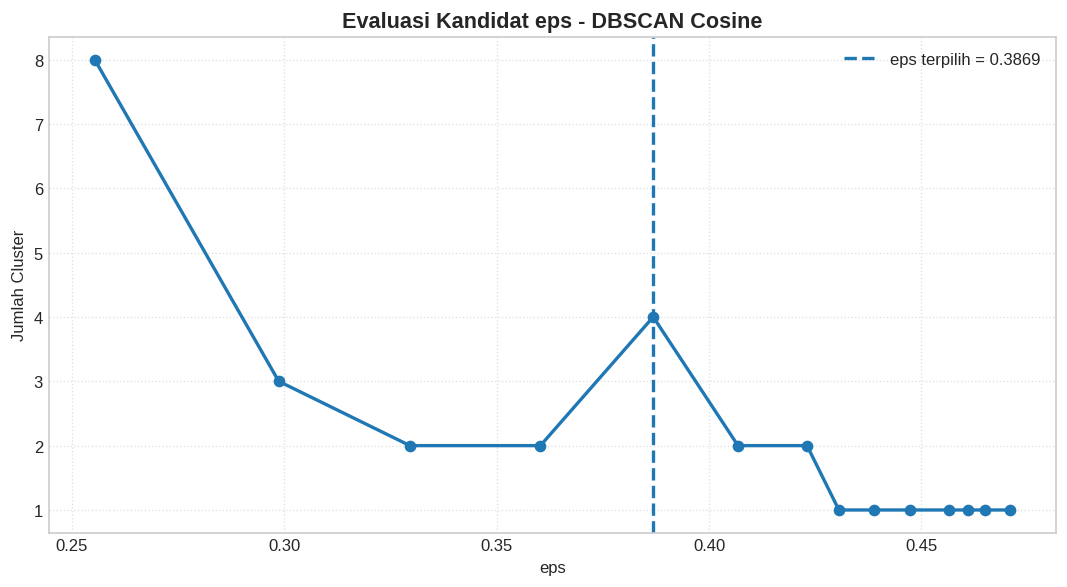

In [22]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    eps_evaluation[
        'eps'
    ],
    eps_evaluation[
        'Jumlah Cluster'
    ],
    marker='o',
    linewidth=2
)

plt.axvline(
    x=eps,
    linestyle='--',
    linewidth=2,
    label=(
        f'eps terpilih = '
        f'{eps:.4f}'
    )
)

plt.title(
    'Evaluasi Kandidat eps - '
    'DBSCAN Cosine',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('eps')
plt.ylabel('Jumlah Cluster')

plt.grid(
    True,
    linestyle=':',
    alpha=0.6
)

plt.legend()

plt.tight_layout()

plt.show()

3.2 Training DBSCAN Cosine

In [23]:
tracemalloc.start()

start_time = time.perf_counter()

dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples,
    metric='cosine'
)

labels = dbscan.fit_predict(
    X_scaled
)

runtime = (
    time.perf_counter()
    - start_time
)

current_memory, peak_memory = (
    tracemalloc.get_traced_memory()
)

tracemalloc.stop()

peak_memory_mb = (
    peak_memory
    / (1024 ** 2)
)

df[
    'DBSCAN_Cluster'
] = labels

print(
    f'Runtime     : '
    f'{runtime:.5f} detik'
)

print(
    f'Peak Memory : '
    f'{peak_memory_mb:.2f} MB'
)

Runtime     : 0.54642 detik
Peak Memory : 383.84 MB


3.3 Identifikasi Cluster dan Noise

In [24]:
n_clusters = len(
    set(labels)
) - (
    1
    if -1 in labels
    else 0
)

n_noise = np.sum(
    labels == -1
)

noise_percentage = (
    n_noise
    / len(labels)
    * 100
)

n_core_points = len(
    dbscan.core_sample_indices_
)

print(
    f'Jumlah Cluster : '
    f'{n_clusters}'
)

print(
    f'Jumlah Noise   : '
    f'{n_noise}'
)

print(
    f'Persentase Noise: '
    f'{noise_percentage:.2f}%'
)

print(
    f'Core Points    : '
    f'{n_core_points}'
)

Jumlah Cluster : 4
Jumlah Noise   : 1114
Persentase Noise: 22.28%
Core Points    : 2500


4. Evaluasi

4.1 Silhouette Score

In [25]:
mask = labels != -1

X_valid = X_scaled.loc[
    mask
]

labels_valid = labels[
    mask
]

valid_cluster_count = len(
    np.unique(
        labels_valid
    )
)

if valid_cluster_count >= 2:

    silhouette = float(
        silhouette_score(
            X_valid,
            labels_valid,
            metric='cosine'
        )
    )

else:

    silhouette = np.nan

print(
    f'Silhouette Score: '
    f'{silhouette:.4f}'
)

Silhouette Score: 0.1461


4.2 Davies-Bouldin Index

In [26]:
if valid_cluster_count >= 2:

    db_index = float(
        davies_bouldin_score(
            X_valid,
            labels_valid
        )
    )

else:

    db_index = np.nan

print(
    f'Davies-Bouldin Index: '
    f'{db_index:.4f}'
)

Davies-Bouldin Index: 1.8416


4.3 Calinski-Harabasz Index

In [27]:
if valid_cluster_count >= 2:

    ch_index = float(
        calinski_harabasz_score(
            X_valid,
            labels_valid
        )
    )

else:

    ch_index = np.nan

print(
    f'Calinski-Harabasz Index: '
    f'{ch_index:.2f}'
)

Calinski-Harabasz Index: 398.42


4.4 Distribusi Cluster

In [28]:
cluster_distribution = (
    df[
        'DBSCAN_Cluster'
    ]
    .value_counts()
    .sort_index()
)

cluster_distribution

,count
DBSCAN_Cluster,
-1,1114
0,1614
1,2256
2,8
3,8


4.5 Ringkasan Evaluasi

In [29]:
model_summary = pd.DataFrame([{
    'Model':
        'DBSCAN Cosine',

    'Distance Metric':
        'Cosine Distance',

    'eps':
        round(
            eps,
            4
        ),

    'min_samples':
        min_samples,

    'Jumlah Cluster':
        n_clusters,

    'Jumlah Noise':
        n_noise,

    'Noise (%)':
        round(
            noise_percentage,
            2
        ),

    'Silhouette Score (↑)':
        round(
            silhouette,
            4
        ),

    'Davies-Bouldin Index (↓)':
        round(
            db_index,
            4
        ),

    'Calinski-Harabasz Index (↑)':
        round(
            ch_index,
            2
        ),

    'Execution Time (s) (↓)':
        round(
            runtime,
            5
        ),

    'Alokasi Memori (MB)':
        round(
            peak_memory_mb,
            2
        )
}])

model_summary

,Model,Distance Metric,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Execution Time (s) (↓),Alokasi Memori (MB)
0,DBSCAN Cosine,Cosine Distance,0.3869,10,4,1114,22.28,0.1461,1.8416,398.42,0.54642,383.84


4.6 Export Hasil

In [30]:
excel_path = os.path.join(
    OUTPUT_DIR,
    'evaluasi_dbscan_Cosine.xlsx'
)

df_clustered = df.copy()

df_clustered[
    'DBSCAN_Cluster'
] = labels

with pd.ExcelWriter(
    excel_path,
    engine='openpyxl'
) as writer:

    model_summary.to_excel(
        writer,
        sheet_name='Ringkasan_Evaluasi',
        index=False
    )

    df_clustered.to_excel(
        writer,
        sheet_name='Data_Terklaster',
        index=False
    )

print(
    f'Hasil disimpan ke: '
    f'{excel_path}'
)

Hasil disimpan ke: outputDBscanCosine/evaluasi_dbscan_Cosine.xlsx


5. PCA

5.1 PCA

In [31]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_scaled
)

5.2 Visualisasi DBSCAN

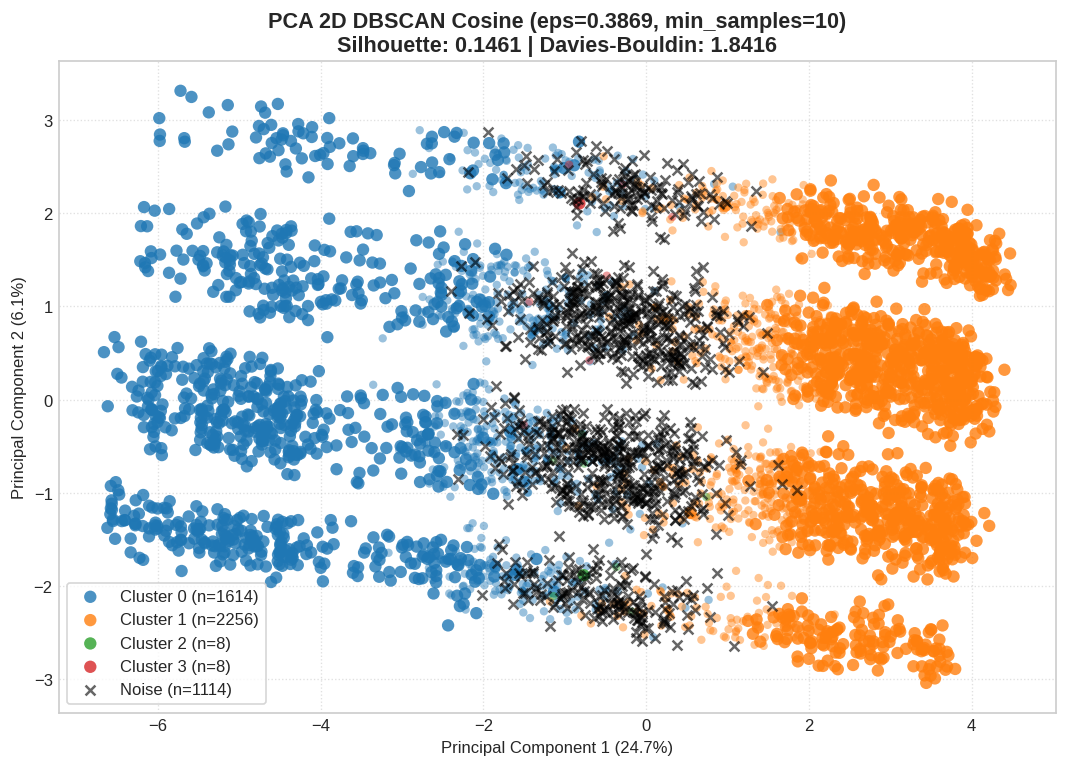

In [32]:
plt.figure(
    figsize=(9, 6.5)
)

palette = sns.color_palette(
    'tab10',
    max(
        n_clusters,
        1
    )
)

core_samples_mask = np.zeros(
    len(labels),
    dtype=bool
)

core_samples_mask[
    dbscan.core_sample_indices_
] = True

for k in range(
    n_clusters
):

    cluster_mask = (
        labels == k
    )

    core_mask = (
        cluster_mask
        & core_samples_mask
    )

    border_mask = (
        cluster_mask
        & ~core_samples_mask
    )

    # Core points
    plt.scatter(
        X_pca[
            core_mask,
            0
        ],
        X_pca[
            core_mask,
            1
        ],
        color=palette[k],
        s=55,
        alpha=0.80,
        edgecolors='none',
        label=(
            f'Cluster {k} '
            f'(n={np.sum(cluster_mask)})'
        )
    )

    # Border points
    plt.scatter(
        X_pca[
            border_mask,
            0
        ],
        X_pca[
            border_mask,
            1
        ],
        color=palette[k],
        s=25,
        alpha=0.45,
        edgecolors='none'
    )

# Noise
noise_mask = (
    labels == -1
)

plt.scatter(
    X_pca[
        noise_mask,
        0
    ],
    X_pca[
        noise_mask,
        1
    ],
    c='black',
    marker='x',
    s=35,
    alpha=0.60,
    label=(
        f'Noise '
        f'(n={np.sum(noise_mask)})'
    )
)

plt.title(
    f'PCA 2D DBSCAN Cosine '
    f'(eps={eps:.4f}, '
    f'min_samples={min_samples})\n'
    f'Silhouette: '
    f'{silhouette:.4f} | '
    f'Davies-Bouldin: '
    f'{db_index:.4f}',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Principal Component 1 '
    f'('
    f'{pca.explained_variance_ratio_[0] * 100:.1f}%'
    f')'
)

plt.ylabel(
    'Principal Component 2 '
    f'('
    f'{pca.explained_variance_ratio_[1] * 100:.1f}%'
    f')'
)

plt.grid(
    True,
    linestyle=':',
    alpha=0.6
)

plt.legend(
    frameon=True,
    loc='best'
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        'cluster_dbscan_cosine.png'
    ),
    dpi=300
)

plt.show()

6. Analisis

6.1 Profil Cluster

In [33]:
df_analysis = X.copy()

df_analysis[
    'DBSCAN_Cluster'
] = labels

cluster_profile = (
    df_analysis[
        df_analysis[
            'DBSCAN_Cluster'
        ] != -1
    ]
    .groupby(
        'DBSCAN_Cluster'
    )
    .median()
)

cluster_profile

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
DBSCAN_Cluster,,,,,,,,,,,,,,,,,,,,,
0,41.0,6282.846197,58.0,6.0,5.52004,6.3,68.0,68.0,33.0,31.0,...,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0
1,42.0,6282.846197,34.0,6.0,6.00000,7.5,18.0,18.0,82.0,82.0,...,0.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,24.5,5918.500000,53.0,5.0,9.00000,5.0,42.5,43.5,56.5,59.5,...,1.0,1.5,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
3,26.0,10227.500000,59.5,4.0,7.50000,9.0,53.5,55.0,49.5,42.5,...,1.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


6.2 Perbandingan Cluster dengan Burnout Risk

In [34]:
comparison = pd.crosstab(
    df['DBSCAN_Cluster'],
    df['Burnout_Risk']
)

comparison

comparison_percentage = pd.crosstab(
    df['DBSCAN_Cluster'],
    df['Burnout_Risk'],
    normalize='index'
) * 100

comparison_percentage.round(
    2
)

Burnout_Risk,High,Low,Moderate
DBSCAN_Cluster,,,
-1,2.60,31.69,65.71
0,60.53,1.55,37.92
1,0.00,93.09,6.91
2,0.00,0.00,100.00
3,12.50,37.50,50.00


6.3 Analisis Noise

In [35]:
noise_data = df[
    df[
        'DBSCAN_Cluster'
    ] == -1
]

print(
    f'Jumlah Noise: '
    f'{len(noise_data)}'
)

print(
    f'Persentase Noise: '
    f'{len(noise_data) / len(df) * 100:.2f}%'
)

noise_data.head()

Jumlah Noise: 1114
Persentase Noise: 22.28%


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk,DBSCAN_Cluster
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate,-1
6,10823,39.0,Female,Brazil,Student,Bachelor,Employed,NaN,64,No,...,No,Excellent,3.0,37.0,18,29,Healthy,Increase Physical Activity,Low,-1
14,18472,63.0,Male,Germany,Designer,Master,Student,NaN,23,No,...,Yes,Poor,9.0,43.0,20,31,Healthy,Seek Professional Support,Low,-1
18,12610,55.0,Male,United States,Doctor,PhD,Employed,NaN,42,Hybrid,...,No,Poor,5.0,47.0,1,35,Healthy,Increase Physical Activity,Low,-1
21,15909,45.0,Female,France,Lawyer,Diploma,Self-Employed,NaN,54,Yes,...,No,Excellent,3.0,78.0,9,43,Needs Attention,Improve Sleep,Moderate,-1
